# Notebook 1 — Exploration des données (simulations `quentin_house`)

Objectif : prédire les indicateurs thermiques HLC, $H_b$ et $\tau$ d'un bâtiment à partir des séries $T_{int}(t)$ et $U(t)$. Ce notebook explore les données avant la modélisation.

**Sommaire**
0. Compréhension physique du problème
1. Les données
2. L'excitation $U(t)$
3. La réponse $T_{int}(t)$
4. Les simulations et les cibles
5. Ce que la réponse dit des cibles
6. Représentativité de `batch_1`
7. Bilan et décisions pour la modélisation

Chaque section se termine par ses conclusions. Sauf mention contraire, les chiffres portent sur `batch_1` (50 000 simulations).

# 0. Compréhension physique du problème

## 0.1 Objectif

Identifier les caractéristiques thermiques intrinsèques d'un bâtiment — $\text{HLC}$, $H_b = (\text{HLC}_{mit}, \text{HLC}_{ext})$, $\tau_b$, $\tau_n$, $\tau_\infty$ — à partir de deux séries mesurées sur quelques heures : la puissance de chauffage $U(t)$ et la température de l'air intérieur $T_{int}(t)$. Ces indicateurs ne se mesurent pas directement : on simule une population de bâtiments pour apprendre le lien entre les courbes et les indicateurs (approche *simulation-driven ML*, Nassif et al., coEnergy).

## 0.2 Deux lois physiques

- **Loi de Fourier** : la chaleur va du chaud vers le froid, avec un flux proportionnel à l'écart, $\Phi = G \cdot \Delta T$.
- **Conservation de l'énergie** : ce qui entre dans un volume sans en ressortir y est stocké, $C \, \dfrac{dT}{dt} = \sum \Phi_{entrants}$.

Ces deux lois ont la forme d'un circuit électrique de résistances et de condensateurs : c'est le **modèle RC**.

| Thermique | Électrique |
|---|---|
| Température $T$ (K) | Tension |
| Flux $\Phi$ (W) | Courant |
| Résistance $R = e/(\lambda S)$ (K/W) | Résistance |
| Capacité $C = \rho c_p e S$ (J/K) | Condensateur |
| Chauffage $P(t)$ | Source de courant |
| $T_{ext}$, $T_{mit}$ | Sources de tension |

## 0.3 Discrétisation du bâtiment en nœuds

| Élément | Traitement | Raison |
|---|---|---|
| Murs massifs (béton, pierre) | découpés en tranches, une température par tranche | la chaleur y pénètre lentement |
| Surfaces intérieures / extérieures | nœuds échangeant par convection et rayonnement | le soleil et l'infrarouge agissent sur les surfaces |
| Air de la zone | un nœud de faible capacité | c'est $T_{int}$, la grandeur mesurée |
| Vitrages, ponts thermiques, isolant léger | une conductance seule, sans nœud | masse négligeable |
| Extérieur, sol, zones mitoyennes | entrées imposées | frontières du système |

L'isolant porte l'essentiel de la **résistance** (donc du HLC), le béton l'essentiel de la **capacité** (donc des constantes de temps).

## 0.4 Un bilan d'énergie par nœud

$$
C_i \frac{dT_i}{dt} = \sum_{j \in \text{voisins}} G_{ij}\,(T_j - T_i) + \sum_{b \in \text{frontières}} G_{ib}\,(T_b - T_i) + \text{sources}_i(t)
$$

## 0.5 Représentation d'état

$$
C\,\dot{T} = A\,T + E\,U \qquad\qquad Y = J\,T + G\,U
$$

| Élément | Contenu |
|---|---|
| $T \in \mathbb{R}^n$ | températures de tous les nœuds (l'état, la « mémoire » du bâtiment) |
| $U \in \mathbb{R}^m$ | entrées : $T_{ext}$, $T_{mit}$, soleil, puissance de chauffage $P$ |
| $C$ | capacités (diagonale) |
| $A$ | conductances entre nœuds : symétrique, diagonale négative |
| $E$ | couplage des entrées sur chaque nœud |
| $J$ | sélection des sorties observées (ici l'air de la zone) |
| $G$ | transmission directe entrée → sortie (nulle pour l'air) |

## 0.6 Ce que les matrices donnent directement

**Régime permanent** ($\dot T = 0$) :

$$
S = G - J\,A^{-1}E, \qquad \text{HLC} = \frac{1}{[S]_{T_{int},\,P}}
$$

Les autres coefficients de $S$ donnent la répartition des pertes entre frontières, donc $H_b$, avec la contrainte exacte $\text{HLC} = \text{HLC}_{ext} + \text{HLC}_{mit}$ (vérifiée sur les données à $3\cdot10^{-5}$ W/K près). **HLC et $H_b$ ne dépendent que des conductances** : la masse retarde l'équilibre sans le changer.

**Dynamique** : les valeurs propres $\lambda_i$ de $C^{-1}A$ (réelles et négatives) donnent les modes du bâtiment, $\tau_i = -1/\lambda_i$, de quelques minutes (l'air) à plusieurs jours (toute la masse à travers l'isolant). Les constantes de temps demandées sont trois expériences virtuelles sur ce système :

- $\tau_b$ : décharge libre après une saturation uniforme (inertie structurelle) ;
- $\tau_n$ : relaxation après 8 h de refroidissement de l'air (confort d'été) ;
- $\tau_\infty$ : limite de $\tau_n$ pour une sollicitation infinie.

Elles dépendent **des conductances et des capacités**. *La convention exacte de calcul (intégrale de la relaxation ou temps à $1/e$) n'est pas précisée dans l'énoncé.*

## 0.7 Simulation

Avec un pas $\Delta t$ et des entrées constantes sur le pas :

$$
T_{k+1} = \Phi\,T_k + \Gamma\,U_k, \qquad \Phi = e^{C^{-1}A\,\Delta t}, \qquad \Gamma = (C^{-1}A)^{-1}(\Phi - I)\,C^{-1}E
$$

La température simulée est la somme d'une **réponse libre** (l'état initial, qui s'oublie lentement) et d'une **réponse forcée** (chauffage et météo).

## 0.8 Génération du dataset

1. Tirer les paramètres du bâtiment ($\lambda$, $\rho c_p$, $e$, $S$, $\psi$) uniformément à ±60 % des valeurs nominales → $C, A, E$.
2. Calculer les étiquettes à partir des matrices → HLC, $H_b$, $\tau$ (**y**).
3. Tirer une excitation → $U(t)$, dont les paramètres sont dans `solicitation` (le générateur prévoit sinusoïdes et PRBS ; le dataset fourni ne contient que des PRBS, voir section 2).
4. Tirer un état initial des parois → $T(0)$.
5. Intégrer sur 480 pas → $T_{int}(t)$ (**X**).

Le pas de temps est de **1 min** : 480 pas = **8 h par simulation**.

## 0.9 Pourquoi ces indicateurs

- **Utiles** : HLC donne le besoin de chauffage, $H_b$ localise les pertes, les $\tau$ caractérisent l'inertie et le confort.
- **Identifiables** : les paramètres de chaque couche ne se distinguent pas à partir d'une seule température d'air ; ces indicateurs, si.
- **Intrinsèques** : ils ne dépendent que des matrices, ni de la météo ni de l'excitation.
- **Résumé de la réponse** : $1/\text{HLC}$ est l'aire de la réponse impulsionnelle de $T_{int}$ à $P$ ; les $\tau$ décrivent sa répartition dans le temps.

## 0.10 Conséquences pour le modèle de machine learning

Le réseau fait le chemin inverse du simulateur : à partir de $(T_{int}, U)$, retrouver HLC, $H_b$ et $\tau$ sans voir les matrices.

Difficultés attendues (hypothèses à vérifier) :
- en 8 h l'équilibre n'est pas atteint : le HLC doit être extrapolé à partir du début de la réponse ;
- les modes lents ($\tau_b$, $\tau_\infty$) évoluent peu dans la fenêtre : erreurs probablement plus fortes sur ces cibles ;
- l'état initial inconnu se superpose à toute la série.

Leviers :
- les excitations riches (sinus, PRBS) sollicitent plusieurs modes ;
- la contrainte $\text{HLC} = \sum H_b$ peut être imposée par construction (prédire $H_b$, puis sommer) ;
- des sorties positives (softplus) et une normalisation des cibles par famille.

## 0.11 Limites

Conduction 1D, air parfaitement mélangé, coefficients d'échange constants, matériaux secs, pas d'infiltration ni de météo fournie dans le dataset. Les performances mesurées sur des simulations caractérisent la généralisation **à l'intérieur de la population simulée** de `quentin_house`, pas sur un bâtiment réel.

# 1. Les données

Chargement de `batch_1`, formes des tenseurs et contrôles d'intégrité.

In [1]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from thermal_id.paths import RAW_DIR          # data/raw/quentin_house
from thermal_id.simul_io import load_single_batch

b = load_single_batch(RAW_DIR / "batch_1.pt")

T = b.indoor_temperature   # (N, 480) température intérieure
U = b.indoor_U             # (N, 480) puissance de chauffage

cdt_labels = ["tau_b", "tau_n", "tau_inf"]
indicators = torch.cat([b.HLC.unsqueeze(1), b.Hb, b.CDT], dim=1)
indicators_labels = ["HLC"] + list(b.Hb_labels) + cdt_labels
df_y = pd.DataFrame(indicators.numpy(), columns=indicators_labels)
df_s = pd.DataFrame(b.solicitation.numpy(), columns=b.solicitation_field_names)

for name in ["indoor_temperature", "indoor_U", "solicitation", "HLC", "Hb", "CDT"]:
    print(f"{name:20s} {tuple(getattr(b, name).shape)}")
print("Hb_labels :", b.Hb_labels)

# intégrité
has_nan = any(torch.isnan(getattr(b, k)).any().item() for k in ["indoor_temperature", "indoor_U", "HLC", "Hb", "CDT"])
print("valeurs manquantes :", has_nan)
print("max |HLC - sum(Hb)| =", (b.HLC - b.Hb.sum(1)).abs().max().item())

indoor_temperature   (50000, 480)
indoor_U             (50000, 480)
solicitation         (50000, 12)
HLC                  (50000,)
Hb                   (50000, 2)
CDT                  (50000, 3)
Hb_labels : ['HLC_mit', 'HLC_ext']
valeurs manquantes : False
max |HLC - sum(Hb)| = 3.0517578125e-05


## 1.1 Rôle de chaque tenseur

Chaque ligne des tenseurs correspond à **une simulation** (ici 50 000 par batch).

| Tenseur | Forme | Rôle | Signification |
|---|---|---|---|
| `indoor_temperature` | (50000, 480) | **entrée** | $T_{int}(t)$ : température de l'air intérieur (°C), la série mesurée |
| `indoor_U` | (50000, 480) | **entrée** | $U(t)$ : la sollicitation, c'est-à-dire la puissance de chauffage injectée (W) |
| `solicitation` | (50000, 12) | métadonnées | les 12 paramètres du générateur qui a produit $U(t)$ |
| `HLC` | (50000,) | **cible** | coefficient de déperdition thermique (W/K) |
| `Hb` | (50000, 2) | **cible** | décomposition du HLC : `HLC_mit` (vers les zones mitoyennes) et `HLC_ext` (vers l'extérieur) |
| `CDT` | (50000, 3) | **cible** | les trois constantes de temps $\tau_b$, $\tau_n$, $\tau_\infty$ (heures) |

## 1.2 Pourquoi 480 valeurs par simulation ?

L'acquisition se fait **toutes les minutes pendant 8 heures** : $8 \times 60 = 480$ pas de temps.
Chaque simulation est donc une expérience de 8 h, échantillonnée à 1 min, et $T_{int}$ et $U$ sont deux séries synchrones de 480 points.

## 1.3 Température intérieure et sollicitation

- `indoor_temperature` : la température de l'air du bâtiment, la **réponse** du bâtiment.
- `indoor_U` : la **sollicitation**, la puissance de chauffage qui excite le bâtiment. Le bâtiment réagit à $U$ selon ses propriétés thermiques, ce qui rend ses caractéristiques identifiables.

## 1.4 À quoi servent les 12 paramètres de `solicitation` ?

Il y a **une seule sollicitation par simulation** : c'est la ligne de `indoor_U`.
Les 12 valeurs sont la « recette » qui l'a générée (amplitudes, périodes, phase pour la sinusoïde ; durées de créneaux, probabilité et graine pour le PRBS ; puissance maximale). Elles ne sont **pas des entrées utiles au modèle** : toute l'information est déjà dans `indoor_U`. Elles servent à **analyser** les résultats, par exemple classer les simulations par type d'excitation et comparer l'erreur selon ce type.

## 1.5 Les cibles

- **`HLC`** : le coefficient de déperdition total (W/K), régime permanent.
- **`Hb`** : sa répartition entre `HLC_mit` et `HLC_ext`, avec la contrainte $\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$.
- **`CDT`** : les trois paramètres temporels $\tau_b$, $\tau_n$, $\tau_\infty$, qui décrivent l'inertie du bâtiment (dynamique).

Le modèle doit prédire ces **6 valeurs** à partir de $(T_{int}, U)$.

**Intégrité** : aucune valeur manquante, et $\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$ à $3\cdot10^{-5}$ W/K près (précision float32).

# 2. L'excitation $U(t)$

Le bâtiment est un système que l'on **excite** avec une puissance de chauffage $U(t)$ et dont on **observe la réponse** $T_{int}(t)$. Cette section étudie l'excitation : comment elle est générée, quelles formes elle prend, et si elle est bien indépendante du bâtiment.

## 2.1 Les 12 paramètres du générateur

Chaque simulation reçoit **une** sollicitation $U(t)$ ; les 12 colonnes de `solicitation` sont les réglages du générateur qui l'a produite. On regarde d'abord lesquels varient réellement.

In [2]:
display(df_s.agg(["min", "max", "nunique"]).T)

print("valeurs prises par U :", torch.unique(U).tolist())
ratio_d = df_s["prbs_max_duration_hours"] / df_s["prbs_min_duration_hours"]
print("max_duration / min_duration :", ratio_d.min(), "à", ratio_d.max())

,min,max,nunique
max_power_wat,7000.000000,7000.000000,1.0
start_amplitude_wat,0.000000,0.000000,1.0
end_amplitude_wat,0.000000,0.000000,1.0
start_period_hours,0.000000,0.000000,1.0
end_period_hours,0.000000,0.000000,1.0
transition_speed,14.000000,14.000000,1.0
phase_shift,0.000000,0.000000,1.0
average_fluctuation_wat,0.000000,0.000000,1.0
prbs_min_duration_hours,0.000025,1.999976,49951.0
prbs_max_duration_hours,0.000050,3.999952,49951.0


valeurs prises par U : [0.0, 7000.0]
max_duration / min_duration : 2.0 à 2.0


**Lecture.** Seuls trois paramètres varient : `prbs_min_duration_hours` (0 à 2 h), `prbs_max_duration_hours` (toujours $2\times$ la durée minimale) et `prbs_probability_on` (0,2 à 0,9). Les paramètres de sinusoïde sont à 0 : **toutes les excitations de ce batch sont des PRBS** (créneaux pseudo-aléatoires), à deux niveaux, 0 W ou `max_power_wat` = 7000 W. La graine `prbs_seed` est la même pour toutes les simulations.

## 2.2 Mécanisme du générateur (reconstitué à partir des données)

Le code du générateur n'est pas fourni. Le fonctionnement suivant est cohérent avec toutes les vérifications ci-dessous :

```
état = arrêt
tant que durée < 8 h :
    d = tirage uniforme dans [min_duration, max_duration]
    maintenir l'état courant pendant d (0 W ou 7000 W)
    état = marche avec la probabilité p_on, sinon arrêt
```

Deux tirages successifs identiques se collent : un créneau observé peut donc durer plus que `max_duration`, mais jamais moins que `min_duration`.

## 2.3 Formes d'excitation obtenues

On résume chaque signal par quelques grandeurs physiques, puis on le classe par famille selon son nombre de commutations.

,count,mean,std,min,25%,50%,75%,max
energie_Wh,50000.0,26269.316406,13676.835938,0.0,17266.666016,29983.333984,36633.332031,56000.0
frac_marche,50000.0,0.469095,0.244229,0.0,0.308333,0.535417,0.654167,1.0
n_commutations,50000.0,6.213360,21.996390,0.0,1.000000,2.000000,3.000000,240.0
premiere_marche_min,50000.0,148.618760,138.974671,0.0,50.000000,106.000000,182.000000,480.0


famille
1 créneau              31.8
1 échelon              29.1
3 à 10 commutations    22.2
sans chauffage          8.5
PRBS rapide (> 10)      7.5
toujours en marche      0.8
Name: % des simulations, dtype: float64

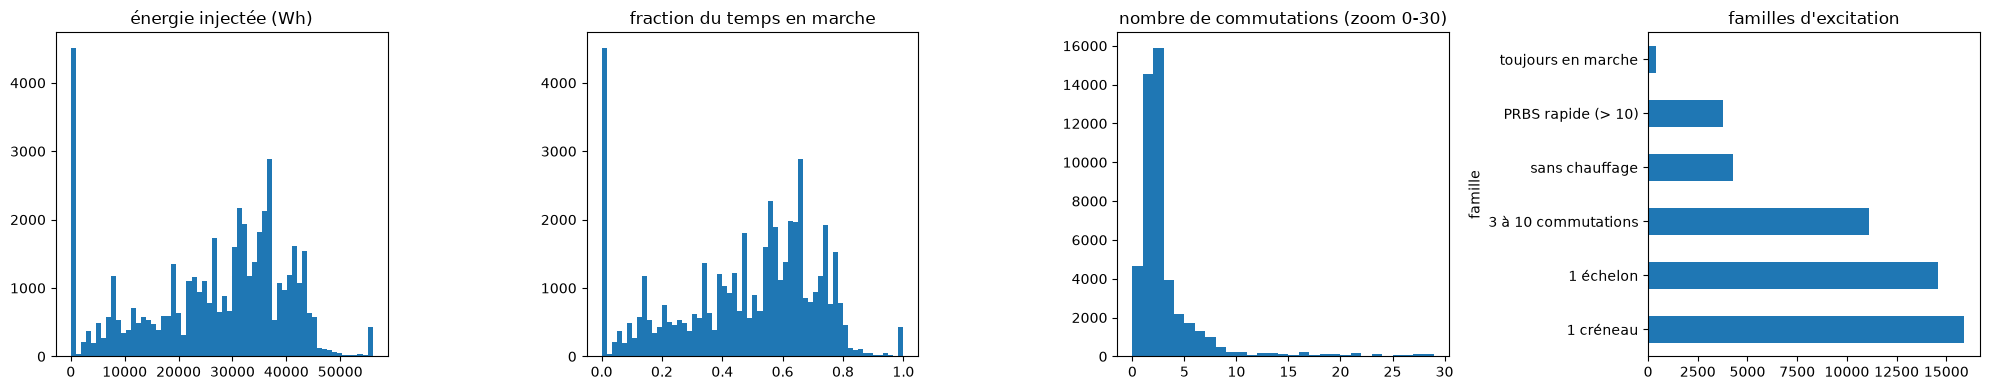

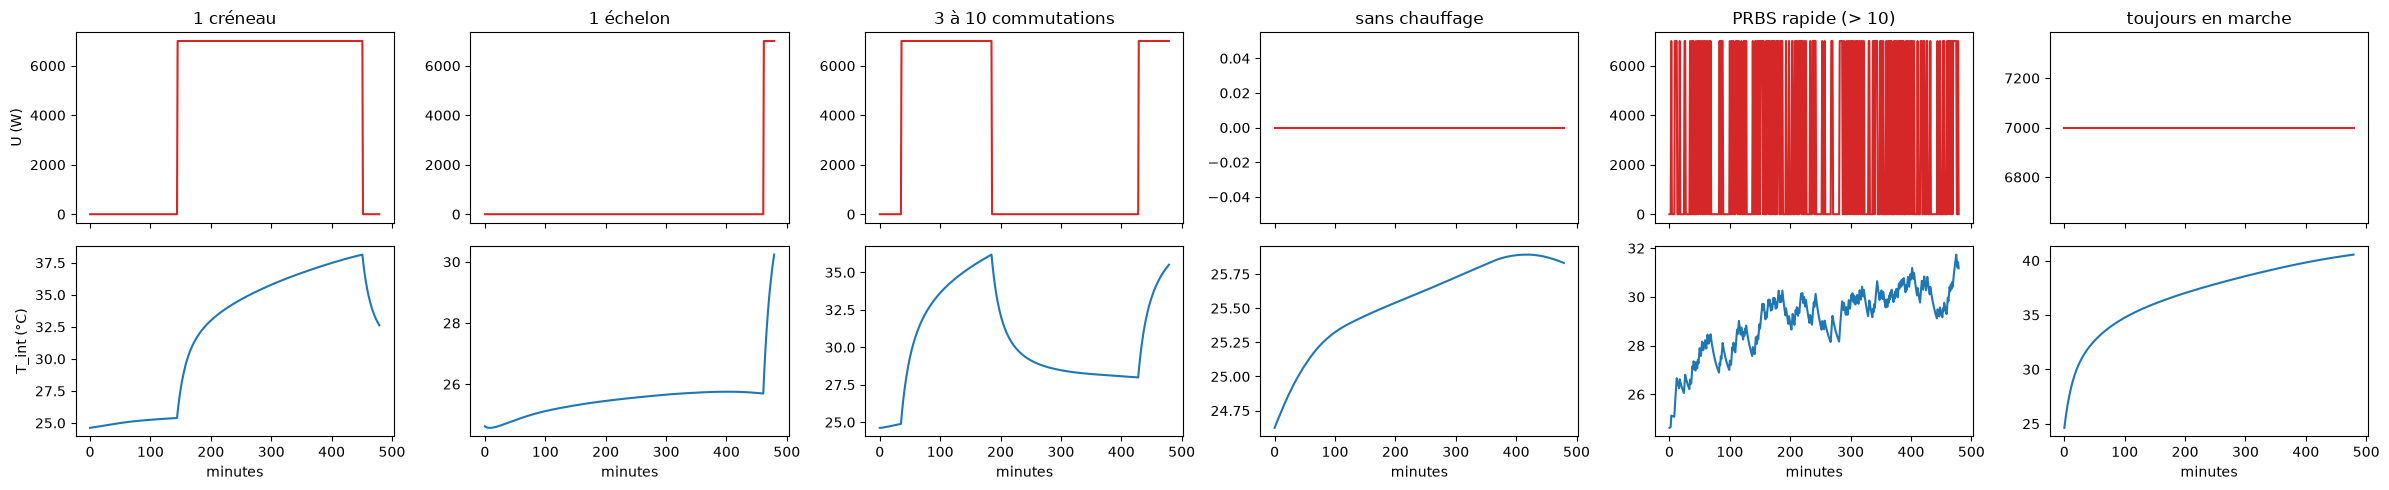

In [3]:
P_ON = df_s["max_power_wat"].iloc[0]
on = U == P_ON                                  # (N, 480) booléen : chauffage en marche
n_sw = (U[:, 1:] != U[:, :-1]).sum(1)           # nombre de commutations marche/arrêt

exc = pd.DataFrame({
    "energie_Wh": (U.sum(1) / 60).numpy(),      # pas de 1 min -> Wh
    "frac_marche": on.float().mean(1).numpy(),
    "n_commutations": n_sw.numpy(),
    "premiere_marche_min": torch.where(on.any(1), on.int().argmax(1), torch.tensor(480)).numpy(),
    "marche_debut": on[:, 0].numpy(),
    "marche_fin": on[:, -1].numpy(),
})
display(exc.describe().T)

exc["famille"] = np.select(
    [exc.energie_Wh == 0, exc.frac_marche == 1, exc.n_commutations == 1,
     exc.n_commutations == 2, exc.n_commutations <= 10],
    ["sans chauffage", "toujours en marche", "1 échelon", "1 créneau", "3 à 10 commutations"],
    default="PRBS rapide (> 10)",
)
counts = exc["famille"].value_counts()
display((counts / len(exc) * 100).round(1).rename("% des simulations"))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(exc["energie_Wh"], bins=60); axes[0].set_title("énergie injectée (Wh)")
axes[1].hist(exc["frac_marche"], bins=60); axes[1].set_title("fraction du temps en marche")
axes[2].hist(exc["n_commutations"], bins=range(0, 30)); axes[2].set_title("nombre de commutations (zoom 0-30)")
counts.plot.barh(ax=axes[3]); axes[3].set_title("familles d'excitation")
plt.tight_layout(); plt.show()

# un exemple de chaque famille
fams = list(counts.index)
fig, axes = plt.subplots(2, len(fams), figsize=(4 * len(fams), 5), sharex=True)
for k, f in enumerate(fams):
    i = exc.index[exc.famille == f][0]
    axes[0, k].plot(U[i], color="tab:red"); axes[0, k].set_title(f)
    axes[1, k].plot(T[i]); axes[1, k].set_xlabel("minutes")
axes[0, 0].set_ylabel("U (W)"); axes[1, 0].set_ylabel("T_int (°C)")
plt.tight_layout(); plt.show()

## 2.4 Vérification du mécanisme

Si le mécanisme reconstitué est juste : aucun créneau n'est plus court que `min_duration`, la durée minimale fixe le nombre de commutations, et `p_on` fixe la part du temps en marche.

créneaux plus courts que min_duration : 0 sur 14949 (3000 simulations)
corr de Spearman (min_duration, commutations) = -0.86
corr (p_on, fraction en marche) = 0.76


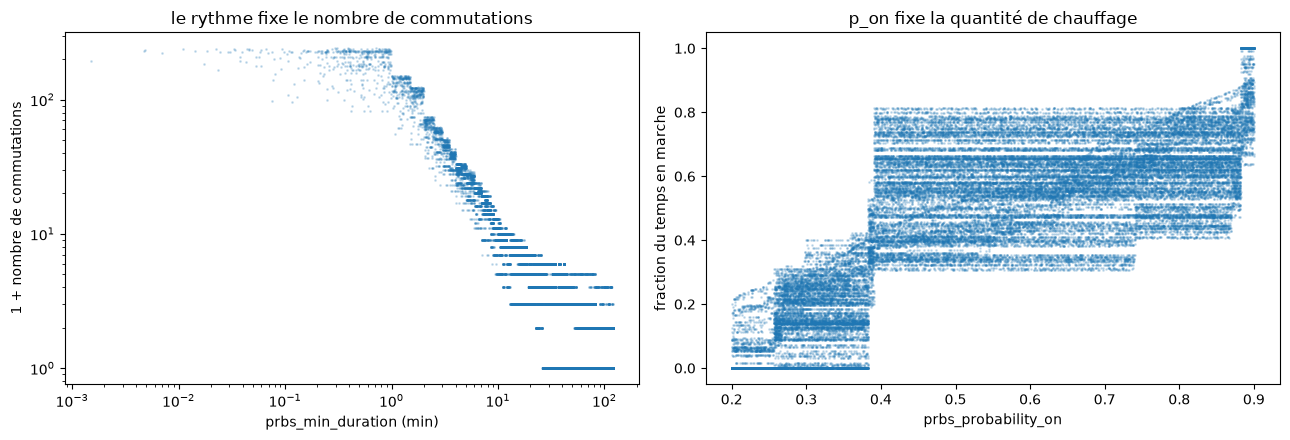

In [4]:
# Vérification du mécanisme : durée minimale des créneaux, rythme et quantité de chauffage
min_d = df_s["prbs_min_duration_hours"] * 60     # en minutes
p_on = df_s["prbs_probability_on"]

n_short = n_tot = 0
for i in range(3000):
    row = U[i]
    change = torch.nonzero(row[1:] != row[:-1]).flatten() + 1
    bounds = torch.cat([torch.tensor([0]), change, torch.tensor([480])])
    lengths = (bounds[1:] - bounds[:-1])[1:-1]   # créneaux internes (le premier et le dernier sont tronqués)
    n_tot += len(lengths)
    n_short += (lengths < min_d[i] - 1).sum().item()
print(f"créneaux plus courts que min_duration : {n_short} sur {n_tot} (3000 simulations)")
print("corr de Spearman (min_duration, commutations) =", round(min_d.rank().corr(exc["n_commutations"].rank()), 2))   # Spearman = Pearson sur les rangs
print("corr (p_on, fraction en marche) =", round(p_on.corr(exc["frac_marche"]), 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(min_d, exc["n_commutations"] + 1, s=1, alpha=0.2)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("prbs_min_duration (min)"); ax[0].set_ylabel("1 + nombre de commutations")
ax[0].set_title("le rythme fixe le nombre de commutations")
ax[1].scatter(p_on, exc["frac_marche"], s=1, alpha=0.2)
ax[1].set_xlabel("prbs_probability_on"); ax[1].set_ylabel("fraction du temps en marche")
ax[1].set_title("p_on fixe la quantité de chauffage")
plt.tight_layout(); plt.show()

## 2.5 Indépendance de l'excitation par rapport au bâtiment

L'excitation doit être tirée indépendamment du bâtiment : sinon le modèle pourrait apprendre les cibles à partir de la forme de $U$ au lieu de la réponse $T_{int}$. On vérifie aussi combien de signaux $U$ distincts existent.

In [5]:
U_uniq, U_id, U_cnt = torch.unique(U, dim=0, return_inverse=True, return_counts=True)
print(f"signaux U distincts : {len(U_uniq)} pour {len(U)} simulations "
      f"(en moyenne {len(U) / len(U_uniq):.0f} bâtiments par signal, max {U_cnt.max().item()} = signal nul)")

feat = pd.concat([exc[["energie_Wh", "frac_marche", "n_commutations", "premiere_marche_min"]],
                  df_s[["prbs_min_duration_hours", "prbs_probability_on"]]], axis=1)
corr_exc_y = pd.concat([feat, df_y], axis=1).corr().loc[feat.columns, indicators_labels]
display(corr_exc_y.round(3))
print("|corr| max entre excitation et cibles :", round(corr_exc_y.abs().values.max(), 3))

signaux U distincts : 2243 pour 50000 simulations (en moyenne 22 bâtiments par signal, max 4248 = signal nul)


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
energie_Wh,0.000,0.002,-0.003,-0.002,0.003,0.000
frac_marche,0.000,0.002,-0.003,-0.002,0.003,0.000
n_commutations,0.005,0.009,-0.005,-0.003,-0.003,-0.004
premiere_marche_min,-0.004,-0.005,0.001,0.001,-0.000,0.000
prbs_min_duration_hours,-0.005,-0.004,-0.004,0.000,0.003,0.001
prbs_probability_on,-0.003,-0.003,-0.001,0.003,0.005,0.003


|corr| max entre excitation et cibles : 0.009


### Conclusions de la section 2

| Constat (batch 1) | Valeur | Conséquence |
|---|---|---|
| Type d'excitation | 100 % PRBS, 0 W ou 7000 W | aucune sinusoïde (confirmé sur `batch_2` et `batch_10`, section 6) |
| Paramètres actifs | `min_duration` (rythme) et `p_on` (quantité) | ce sont les deux axes pour analyser l'erreur du modèle |
| Mécanisme | 0 créneau plus court que `min_duration` ; Spearman(min_duration, commutations) = −0,86 ; corr(p_on, fraction en marche) = 0,76 | le générateur reconstitué est cohérent avec les données |
| Formes | 1 créneau 31,8 %, 1 échelon 29,1 %, 3 à 10 commutations 22,2 %, PRBS rapide 7,5 % | la plupart des simulations sont des **réponses à un échelon ou à un créneau** : `min_duration` médiane ≈ 1 h, donc 1 à 3 créneaux en 8 h |
| Cas limites | 8,5 % sans chauffage, 0,8 % toujours en marche | sans chauffage, seule la dérive libre informe sur le bâtiment : à évaluer à part |
| Réutilisation | 2243 signaux $U$ distincts pour 50 000 simulations (≈ 22 bâtiments par signal) | conséquence probable de la graine fixe ; permet de **comparer des bâtiments à excitation identique** |
| Indépendance | $\lvert \text{corr} \rvert \le 0{,}01$ entre toute grandeur d'excitation et toute cible | pas de biais de génération : l'information sur le bâtiment est dans la réponse $T_{int}$, pas dans $U$ |

# 3. La réponse $T_{int}(t)$

La réponse n'est pas instantanée (inertie du bâtiment) : un nuage $T_{int} = f(U)$ mélangerait des états thermiques différents. On observe donc :
1. les séries superposées pour des bâtiments de HLC très différents ;
2. la variation $\Delta T(t) = T_{int}(t) - T_{int}(0)$ en fonction de l'énergie cumulée injectée ;
3. la corrélation croisée entre $U$ et $T_{int}$ pour estimer le retard de la réponse.

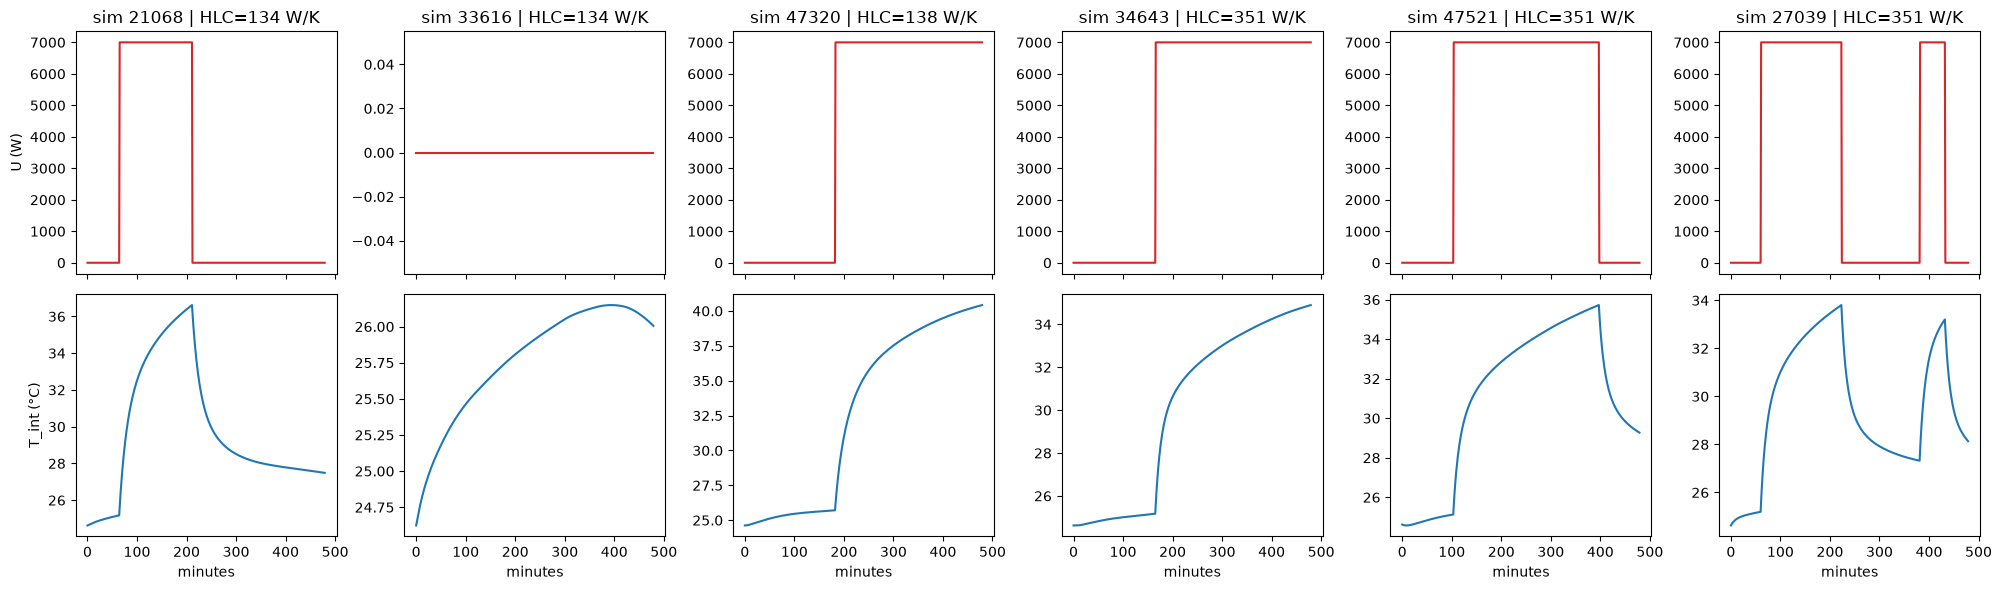

In [6]:
# 1) Séries superposées : 3 HLC les plus faibles et 3 HLC les plus forts
order = torch.argsort(b.HLC)
idx_hlc = torch.cat([order[:3], order[-3:]]).tolist()
t_min = torch.arange(T.shape[1])

fig, axes = plt.subplots(2, 6, figsize=(20, 6), sharex=True)
for k, i in enumerate(idx_hlc):
    axes[0, k].plot(t_min, U[i], color="tab:red")
    axes[0, k].set_title(f"sim {i} | HLC={b.HLC[i]:.0f} W/K")
    axes[1, k].plot(t_min, T[i])
    axes[1, k].set_xlabel("minutes")
axes[0, 0].set_ylabel("U (W)"); axes[1, 0].set_ylabel("T_int (°C)")
plt.tight_layout(); plt.show()

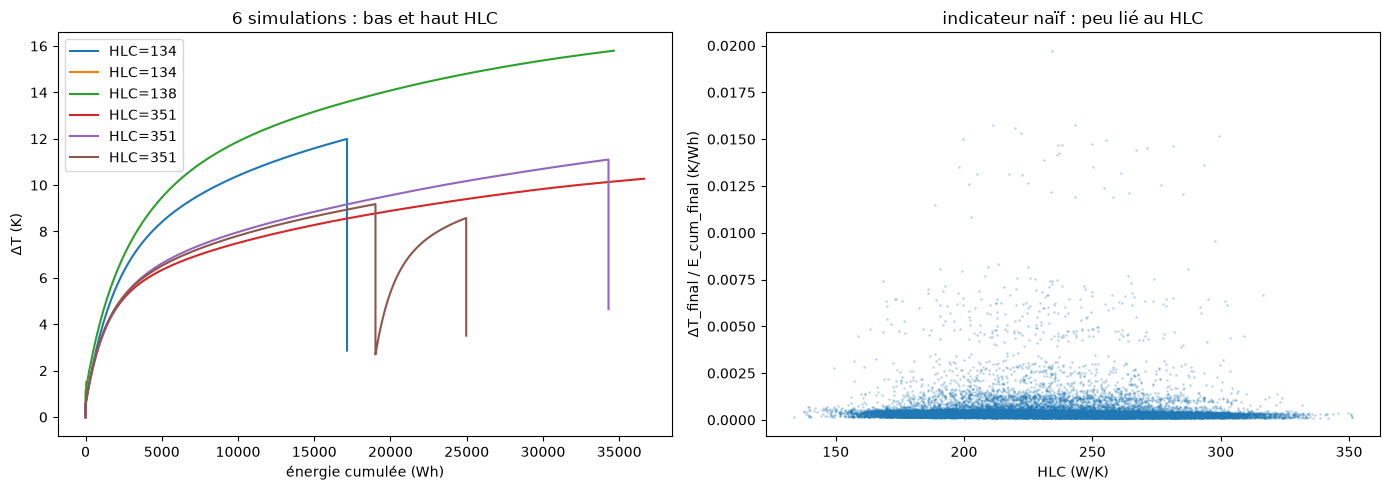

simulations sans chauffage : 4248
corr(ratio, HLC) = -0.03708899766206741


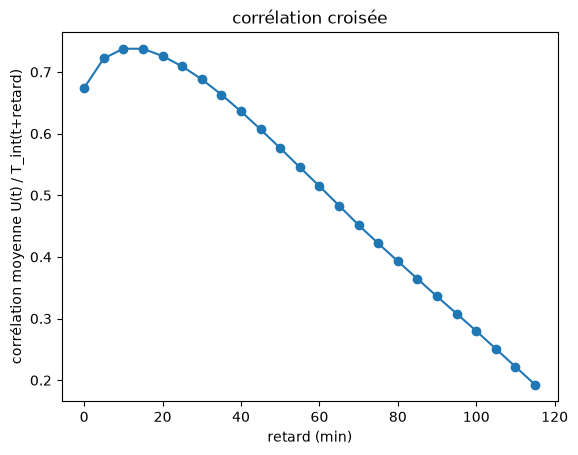

In [7]:
# 2) ΔT en fonction de l'énergie cumulée (Wh), pas de temps = 1 min
dt_h = 1 / 60
E_cum = torch.cumsum(U, dim=1) * dt_h          # (N, 480) en Wh
dT = T - T[:, :1]                              # écart à la température initiale

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i in idx_hlc:
    ax[0].plot(E_cum[i], dT[i], label=f"HLC={b.HLC[i]:.0f}")
ax[0].set_xlabel("énergie cumulée (Wh)"); ax[0].set_ylabel("ΔT (K)"); ax[0].legend()
ax[0].set_title("6 simulations : bas et haut HLC")

# vue globale : ΔT_final / E_final vs HLC, uniquement pour les simulations chauffées (E > 0)
heated = E_cum[:, -1] > 0
ratio = dT[heated, -1] / E_cum[heated, -1]
ax[1].scatter(b.HLC[heated], ratio, s=1, alpha=0.2)
ax[1].set_xlabel("HLC (W/K)"); ax[1].set_ylabel("ΔT_final / E_cum_final (K/Wh)")
ax[1].set_title("indicateur naïf : peu lié au HLC")
plt.tight_layout(); plt.show()
print("simulations sans chauffage :", (~heated).sum().item())
print("corr(ratio, HLC) =", torch.corrcoef(torch.stack([ratio, b.HLC[heated]]))[0, 1].item())

# 3) corrélation croisée U -> T_int (sur les séries centrées), moyenne sur 2000 simulations
lags = range(0, 120, 5)
Uc = U[:2000] - U[:2000].mean(1, keepdim=True)
Tc = T[:2000] - T[:2000].mean(1, keepdim=True)
xc = []
for L in lags:
    a, c = (Uc[:, :480 - L], Tc[:, L:]) if L else (Uc, Tc)
    xc.append(((a * c).sum(1) / (a.norm(dim=1) * c.norm(dim=1) + 1e-9)).mean().item())
plt.plot(list(lags), xc, marker="o"); plt.xlabel("retard (min)"); plt.ylabel("corrélation moyenne U(t) / T_int(t+retard)")
plt.title("corrélation croisée"); plt.show()

### Conclusions de la section 3

- **Forme de la réponse** : à chaque mise en marche, $T_{int}$ monte très vite pendant quelques minutes (air, faible capacité), puis lentement (masse des parois). À l'arrêt : chute rapide puis décroissance lente. C'est la signature d'un système RC à plusieurs constantes de temps.
- **État initial** : toutes les simulations partent de 24,624 °C, mais pas à l'équilibre. Sans chauffage, $T_{int}$ monte quand même de 0,4 à 2,3 K en 8 h : une **réponse libre** se superpose à la réponse au chauffage.
- **Retard** : la corrélation croisée $U \to T_{int}$ est maximale (≈ 0,74) pour un retard de 10 à 15 min, puis décroît lentement.
- **Indicateur global naïf** : $\Delta T_{final} / E_{final}$ n'est presque pas corrélé au HLC (≈ −0,04), car la valeur finale dépend surtout de l'instant où le chauffage s'est arrêté.

**Conséquence** : l'information sur le bâtiment est dans la **forme locale** de la réponse autour des commutations, pas dans des valeurs globales. Le modèle doit lire la dynamique de la série (couches convolutives ou récurrentes).

# 4. Les simulations et les cibles

## 4.1 Les simulations sont-elles indépendantes ?

Si plusieurs simulations portaient sur le même bâtiment, ou s'enchaînaient dans le temps, un découpage aléatoire train/test ferait fuiter de l'information. On vérifie :
- l'unicité des vecteurs de cibles (un bâtiment = un jeu d'indicateurs) ;
- l'autocorrélation des cibles selon l'indice de simulation (un effet d'ordre) ;
- les moyennes par blocs de 5000 (une dérive) ;
- l'état initial (une continuité entre simulations).

In [8]:
print("vecteurs de cibles distincts :", torch.unique(indicators, dim=0).shape[0], "/", len(indicators))
print("températures initiales distinctes :", torch.unique(T[:, 0]).tolist())

def acf(x: torch.Tensor, lag: int) -> float:
    """Autocorrélation de x au décalage `lag` (selon l'indice de simulation)."""
    x = x - x.mean()
    return ((x[:-lag] * x[lag:]).sum() / (x * x).sum()).item()

display(pd.DataFrame({f"acf lag {lag}": [acf(indicators[:, j], lag) for j in range(6)] for lag in (1, 10, 100)},
                     index=indicators_labels).round(3))
display(df_y.groupby(np.arange(len(df_y)) // 5000).mean().round(1).rename_axis("bloc de 5000"))

vecteurs de cibles distincts : 50000 / 50000
températures initiales distinctes : [24.624000549316406]


,acf lag 1,acf lag 10,acf lag 100
HLC,0.001,-0.008,0.005
HLC_mit,0.002,-0.010,0.001
HLC_ext,-0.008,-0.000,0.009
tau_b,-0.006,0.001,0.001
tau_n,-0.004,-0.005,-0.001
tau_inf,-0.007,-0.001,-0.001


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
bloc de 5000,,,,,,
0,232.3,120.3,112.1,50.3,11.1,31.5
1,232.9,120.5,112.4,49.8,11.0,31.1
2,233.9,121.3,112.6,49.7,11.0,31.0
3,233.4,121.0,112.4,50.0,11.1,31.3
4,232.9,120.3,112.6,50.1,11.0,31.2
5,233.2,120.4,112.8,50.0,11.0,31.2
6,233.6,120.7,112.9,49.8,11.0,31.1
7,233.4,120.6,112.8,49.8,11.0,31.1
8,232.6,120.2,112.4,50.0,11.1,31.2


**Lecture.** Les 50 000 vecteurs de cibles sont distincts : **un bâtiment différent par simulation**. Les autocorrélations sont inférieures à 0,01 et les moyennes par bloc sont stables (HLC entre 232 et 234 W/K) : l'ordre des simulations est aléatoire. Toutes partent de la même température (24,624 °C) alors que les précédentes finissent entre 25 et 49 °C : aucune continuité.

Remarque : des indicateurs distincts impliquent des bâtiments distincts, mais l'inverse n'est pas vrai. Le passage bâtiment → indicateurs n'est pas injectif (plusieurs combinaisons d'isolant, de vitrages et de masse donnent le même HLC) ; le modèle n'a pas besoin de retrouver le bâtiment, seulement ses indicateurs.

## 4.2 Distribution des cibles

,count,mean,std,min,25%,50%,75%,max
HLC,50000.0,233.08,31.38,133.59,210.68,231.92,254.29,351.19
HLC_mit,50000.0,120.53,26.34,49.81,100.89,118.89,138.48,220.91
HLC_ext,50000.0,112.54,17.16,59.07,100.39,112.23,124.43,174.86
tau_b,50000.0,49.96,10.08,22.49,42.73,48.78,55.90,112.84
tau_n,50000.0,11.04,2.01,5.66,9.61,10.79,12.21,22.98
tau_inf,50000.0,31.21,7.51,11.50,25.82,30.17,35.50,74.84


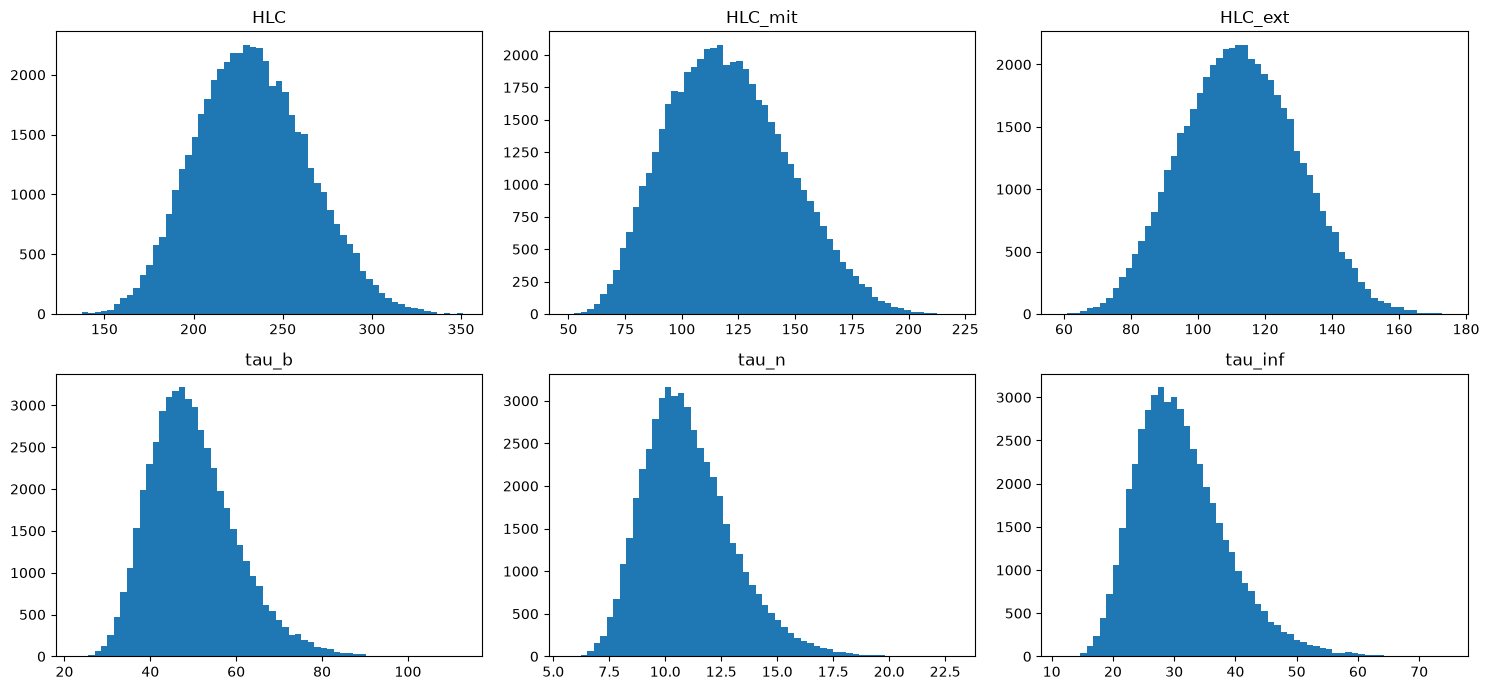

In [9]:
display(df_y.describe().T.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), indicators_labels):
    ax.hist(df_y[col], bins=60)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 4.3 Relations entre les cibles

Les corrélations entre cibles indiquent si certaines sorties sont redondantes ; l'asymétrie des distributions guide la normalisation.

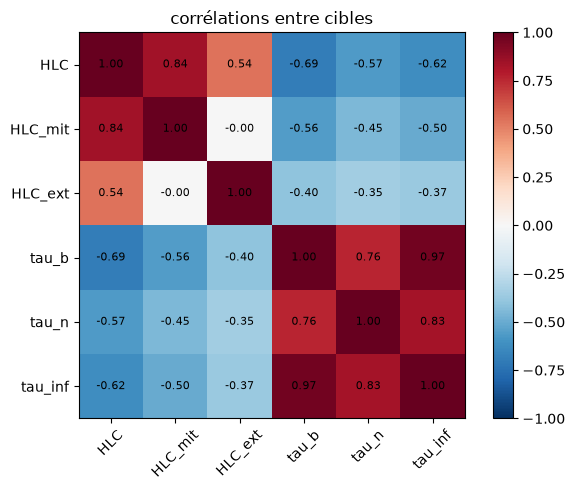

,asymétrie,asymétrie du log,max / min
HLC,0.18,-0.17,2.63
HLC_mit,0.29,-0.23,4.44
HLC_ext,0.10,-0.29,2.96
tau_b,0.71,0.11,5.02
tau_n,0.75,0.20,4.06
tau_inf,0.83,0.13,6.51


In [10]:
def corr_heatmap(ax, c: pd.DataFrame, title: str) -> None:
    """Affiche une matrice de corrélation annotée."""
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(c.shape[1]), c.columns, rotation=45)
    ax.set_yticks(range(c.shape[0]), c.index)
    for i in range(c.shape[0]):
        for j in range(c.shape[1]):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    plt.colorbar(im, ax=ax)

corr_y = df_y.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
corr_heatmap(ax, corr_y, "corrélations entre cibles")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"asymétrie": df_y.skew(),
                      "asymétrie du log": np.log(df_y).skew(),
                      "max / min": df_y.max() / df_y.min()}).round(2))

### Conclusions de la section 4

| Constat | Valeur | Conséquence |
|---|---|---|
| Indépendance des simulations | 50 000 bâtiments distincts, ordre aléatoire, même état initial | pas de fuite de bâtiment ; confirmé entre batches en section 6 |
| `HLC_mit` et `HLC_ext` | corrélation 0,00 | tirés indépendamment : deux sorties réellement distinctes |
| `HLC` | 0,84 avec `HLC_mit`, 0,54 avec `HLC_ext` | redondant par construction ($\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$) : prédire $H_b$ et sommer |
| $\tau_b$ et $\tau_\infty$ | corrélation 0,97 | presque redondants ; $\tau_n$ un peu à part (0,76 et 0,83) |
| HLC et $\tau$ | −0,57 à −0,69 | logique physique : à capacité égale, plus de pertes donne une décharge plus rapide ($\tau \sim C/\text{HLC}$) |
| Asymétrie | HLC ≈ 0,1 à 0,3 ; $\tau$ ≈ 0,7 à 0,8 ; après log, $\tau$ ≈ 0,1 à 0,2 | standardiser les HLC ; passer les $\tau$ en **log** avant de standardiser |
| Étendue | max/min de 2,6 (HLC) à 6,5 ($\tau_\infty$) | une erreur relative (MAPE) est plus parlante qu'une erreur absolue pour comparer les cibles |

# 5. Ce que la réponse $T_{int}$ dit des cibles

## 5.1 Grandeurs de réponse

On résume la réponse par des grandeurs physiques, mesurées autour des commutations (là où l'information se trouve, d'après la section 3) :

| Grandeur | Définition | Ce qu'elle reflète (attendu) |
|---|---|---|
| `derive_libre_30min` | $T(30) - T(0)$ si le chauffage est à l'arrêt pendant les 30 premières minutes | l'état initial du bâtiment |
| `montee_5min` | hausse de $T_{int}$ 5 min après la 1re mise en marche | mode rapide (air) |
| `montee_60min` | hausse de $T_{int}$ 60 min après la 1re mise en marche | modes plus lents, pertes |
| `chute_5min`, `chute_60min` | baisse après le 1er arrêt qui suit une marche | décharge du bâtiment |
| `dT_max`, `dT_final` | écart maximal et final à la température initiale | grandeurs globales |

Une grandeur vaut NaN quand le signal ne contient pas la fenêtre nécessaire (pas de marche, créneau trop court…).

In [11]:
N, L = T.shape
t_idx = torch.arange(L)
has_on = on.any(1)
k_on = on.int().argmax(1)                                          # 1re mise en marche
after_on = (~on) & (t_idx[None, :] > k_on[:, None]) & has_on[:, None]
has_off = after_on.any(1)
k_off = after_on.int().argmax(1)                                   # 1er arrêt après cette marche

def window_ok(state: torch.Tensor, start: torch.Tensor, length: int) -> torch.Tensor:
    """Vrai si `state` reste vrai sur [start, start + length) et que la fenêtre tient dans la série."""
    idx = (start[:, None] + torch.arange(length)).clamp(max=L - 1)
    return (start + length < L) & state.gather(1, idx).all(1)

def delta(start: torch.Tensor, length: int) -> torch.Tensor:
    """T_int(start + length) - T_int(start) pour chaque simulation."""
    end = (start + length).clamp(max=L - 1)
    return T.gather(1, end[:, None])[:, 0] - T.gather(1, start[:, None])[:, 0]

nan = torch.tensor(float("nan"))
feat_r = pd.DataFrame({
    "derive_libre_30min": torch.where((~on[:, :30]).all(1), T[:, 30] - T[:, 0], nan).numpy(),
    "montee_5min": torch.where(has_on & window_ok(on, k_on, 5), delta(k_on, 5), nan).numpy(),
    "montee_60min": torch.where(has_on & window_ok(on, k_on, 60), delta(k_on, 60), nan).numpy(),
    "chute_5min": torch.where(has_off & window_ok(~on, k_off, 5), delta(k_off, 5), nan).numpy(),
    "chute_60min": torch.where(has_off & window_ok(~on, k_off, 60), delta(k_off, 60), nan).numpy(),
    "dT_max": (T.max(1).values - T[:, 0]).numpy(),
    "dT_final": (T[:, -1] - T[:, 0]).numpy(),
})
display(feat_r.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
derive_libre_30min,42257.0,0.249,0.118,-0.265,0.172,0.248,0.323,1.026
montee_5min,44734.0,1.825,0.069,1.285,1.779,1.822,1.868,2.167
montee_60min,37096.0,7.769,0.933,5.364,7.090,7.674,8.342,12.177
chute_5min,30546.0,-1.568,0.322,-1.937,-1.729,-1.668,-1.566,0.436
chute_60min,23736.0,-6.164,1.130,-10.293,-6.863,-6.186,-5.531,-1.222
dT_max,50000.0,11.375,3.916,0.559,10.129,12.167,13.795,24.139
dT_final,50000.0,8.237,4.830,0.448,3.873,8.018,12.605,24.139


## 5.2 Corrélation réponse / cibles, brute et à excitation identique

La réponse dépend **à la fois** du bâtiment et de l'excitation. Une corrélation brute mélange les deux effets. Comme 2243 signaux $U$ sont partagés par plusieurs bâtiments (section 2), on peut retirer l'effet de l'excitation : dans chaque groupe de simulations ayant **exactement le même $U$**, on soustrait la moyenne du groupe aux grandeurs de réponse et aux cibles, puis on calcule la corrélation. Il ne reste alors que les différences dues au bâtiment.

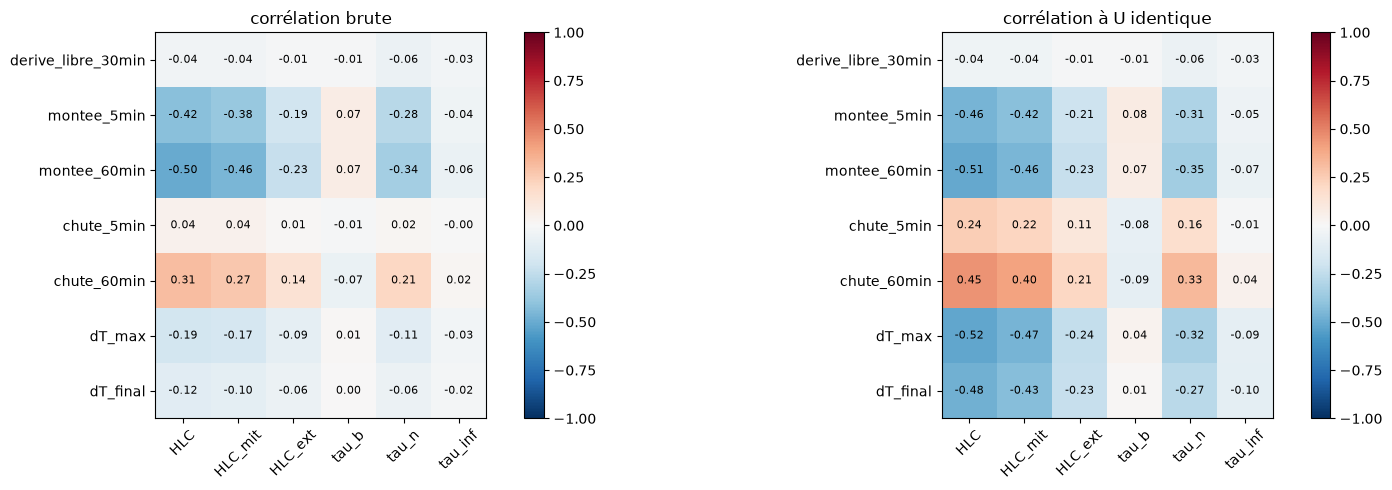

In [12]:
corr_raw = pd.concat([feat_r, df_y], axis=1).corr().loc[feat_r.columns, indicators_labels]

gid = pd.Series(U_id.numpy())                       # identifiant du signal U (section 2)
shared = gid.map(gid.value_counts()) >= 2           # signaux partagés par au moins 2 bâtiments

def demean_by_signal(df: pd.DataFrame) -> pd.DataFrame:
    """Écart de chaque simulation à la moyenne des simulations de même signal U."""
    d = df[shared]
    return d - d.groupby(gid[shared]).transform("mean")

corr_within = (pd.concat([demean_by_signal(feat_r), demean_by_signal(df_y)], axis=1)
               .corr().loc[feat_r.columns, indicators_labels])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr_heatmap(axes[0], corr_raw, "corrélation brute")
corr_heatmap(axes[1], corr_within, "corrélation à U identique")
plt.tight_layout(); plt.show()

## 5.3 Même excitation, bâtiments différents

On prend le signal « 1 échelon » partagé par le plus de bâtiments et on superpose leurs réponses, colorées par HLC.

signal U n°213 : 753 bâtiments


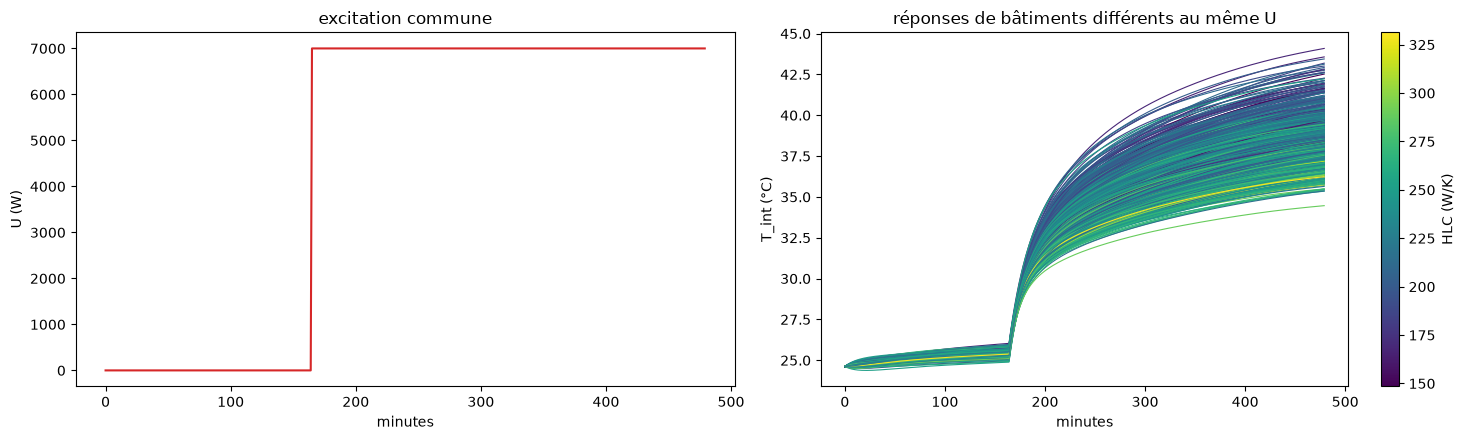

In [13]:
one_step = torch.tensor((exc["famille"] == "1 échelon").values)
g = pd.Series(U_id[one_step].numpy()).value_counts().index[0]
members = torch.nonzero(U_id == g).flatten()
print(f"signal U n°{g} : {len(members)} bâtiments")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(U[members[0]], color="tab:red"); ax[0].set_title("excitation commune"); ax[0].set_ylabel("U (W)")
cmap = plt.get_cmap("viridis")
h = b.HLC[members]
norm = plt.Normalize(h.min().item(), h.max().item())
for i in members.tolist():
    ax[1].plot(T[i], color=cmap(norm(b.HLC[i].item())), lw=0.8)
plt.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax[1], label="HLC (W/K)")
ax[1].set_title("réponses de bâtiments différents au même U"); ax[1].set_ylabel("T_int (°C)")
for a in ax:
    a.set_xlabel("minutes")
plt.tight_layout(); plt.show()

## 5.4 Les constantes de temps sont-elles absentes de la réponse, ou masquées ?

En 5.2, les $\tau$ semblent presque invisibles. Mais un HLC élevé et un $\tau$ élevé n'agissent pas dans le même sens sur la montée, et les deux sont corrélés (−0,69, section 4) : leurs effets peuvent se compenser. On calcule la **corrélation partielle** à HLC fixé : on retire de la montée et de $\tau$ la part expliquée linéairement par le HLC, puis on corrèle les résidus.

In [14]:
def residual(y: np.ndarray, x: np.ndarray) -> np.ndarray:
    """Résidu de la régression linéaire de y sur x."""
    X = np.c_[np.ones_like(x), x]
    return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]

rows = {}
for f in ["montee_5min", "montee_60min", "chute_60min", "dT_max"]:
    m = feat_r[f].notna().values
    x, hlc = feat_r[f].values[m], df_y["HLC"].values[m]
    rows[f] = {f"{c} brute": np.corrcoef(x, df_y[c].values[m])[0, 1] for c in cdt_labels}
    rows[f].update({f"{c} à HLC fixé": np.corrcoef(residual(x, hlc), residual(df_y[c].values[m], hlc))[0, 1]
                    for c in cdt_labels})
display(pd.DataFrame(rows).T.round(2))

,tau_b brute,tau_n brute,tau_inf brute,tau_b à HLC fixé,tau_n à HLC fixé,tau_inf à HLC fixé
montee_5min,0.07,-0.28,-0.04,-0.33,-0.69,-0.43
montee_60min,0.07,-0.34,-0.06,-0.44,-0.89,-0.56
chute_60min,-0.07,0.21,0.02,0.21,0.48,0.28
dT_max,0.01,-0.11,-0.03,-0.16,-0.27,-0.19


### Conclusions de la section 5

**HLC et $H_b$ se lisent directement dans la réponse.** À excitation identique, la montée sur 60 min, l'écart maximal et l'écart final sont corrélés à environ −0,5 avec le HLC : un bâtiment qui perd plus chauffe moins (figure 5.3). `HLC_mit` (−0,46) ressort plus que `HLC_ext` (−0,23).

**Retirer l'effet de l'excitation change les conclusions.** Les grandeurs globales semblaient peu informatives en brut (`dT_final` : −0,12 avec le HLC) ; à $U$ identique, elles le deviennent (−0,48). De même pour `chute_5min` (0,04 → 0,24). Une corrélation brute sous-estime l'information quand l'excitation varie.

**Les $\tau$ sont présents mais masqués par le HLC.** En brut, $\tau_b$ et $\tau_\infty$ semblent absents (|corr| < 0,1). À HLC fixé, la montée sur 60 min est corrélée à −0,44 avec $\tau_b$, −0,56 avec $\tau_\infty$ et **−0,89 avec $\tau_n$**. L'information existe, mais seulement dans une **combinaison** des grandeurs : un modèle linéaire sur une seule grandeur ne la verra pas.

**L'état initial n'informe pas sur le bâtiment.** `derive_libre_30min` est quasiment décorrélée de toutes les cibles (|corr| ≤ 0,06) : la dérive libre est une nuisance à absorber, pas un signal.

# 6. Représentativité de `batch_1` : comparaison avec `batch_2`

Toute l'exploration a été faite sur `batch_1`. Pour l'étendre aux 20 batches, on vérifie sur `batch_2` :
- la même structure et le même type d'excitation ;
- les mêmes distributions de cibles (test de Kolmogorov-Smirnov : écart maximal entre les deux fonctions de répartition) ;
- l'absence de bâtiments communs, qui conditionne le découpage train / validation / test.

mêmes champs de sollicitation : True
paramètres qui varient : ['prbs_min_duration_hours', 'prbs_max_duration_hours', 'prbs_probability_on']


valeurs de U : [0.0, 7000.0] | T0 : [24.624000549316406]
max |HLC - sum(Hb)| : 3.0517578125e-05


,batch_1,batch_2
1 créneau,31.8,31.9
1 échelon,29.1,29.2
3 à 10 commutations,22.2,22.2
sans chauffage,8.5,8.3
PRBS rapide (> 10),7.5,7.6
toujours en marche,0.8,0.9


batch_1                                batch_2                         \
           mean    std     min     50%     max    mean    std     min     50%   
HLC      233.08  31.38  133.59  231.92  351.19  232.72  31.38  123.46  231.64   
HLC_mit  120.53  26.34   49.81  118.89  220.91  120.26  26.30   51.57  118.67   
HLC_ext  112.54  17.16   59.07  112.23  174.86  112.46  17.01   54.91  112.34   
tau_b     49.96  10.08   22.49   48.78  112.84   50.07  10.09   23.67   48.88   
tau_n     11.04   2.01    5.66   10.79   22.98   11.05   2.01    5.50   10.79   
tau_inf   31.21   7.51   11.50   30.17   74.84   31.27   7.53   13.18   30.26   

                 
            max  
HLC      351.69  
HLC_mit  220.00  
HLC_ext  180.05  
tau_b    106.85  
tau_n     24.42  
tau_inf   79.10

HLC        0.0066
HLC_mit    0.0057
HLC_ext    0.0065
tau_b      0.0067
tau_n      0.0043
tau_inf    0.0054
Name: KS, dtype: float64

seuil KS à 5 % : 0.0086


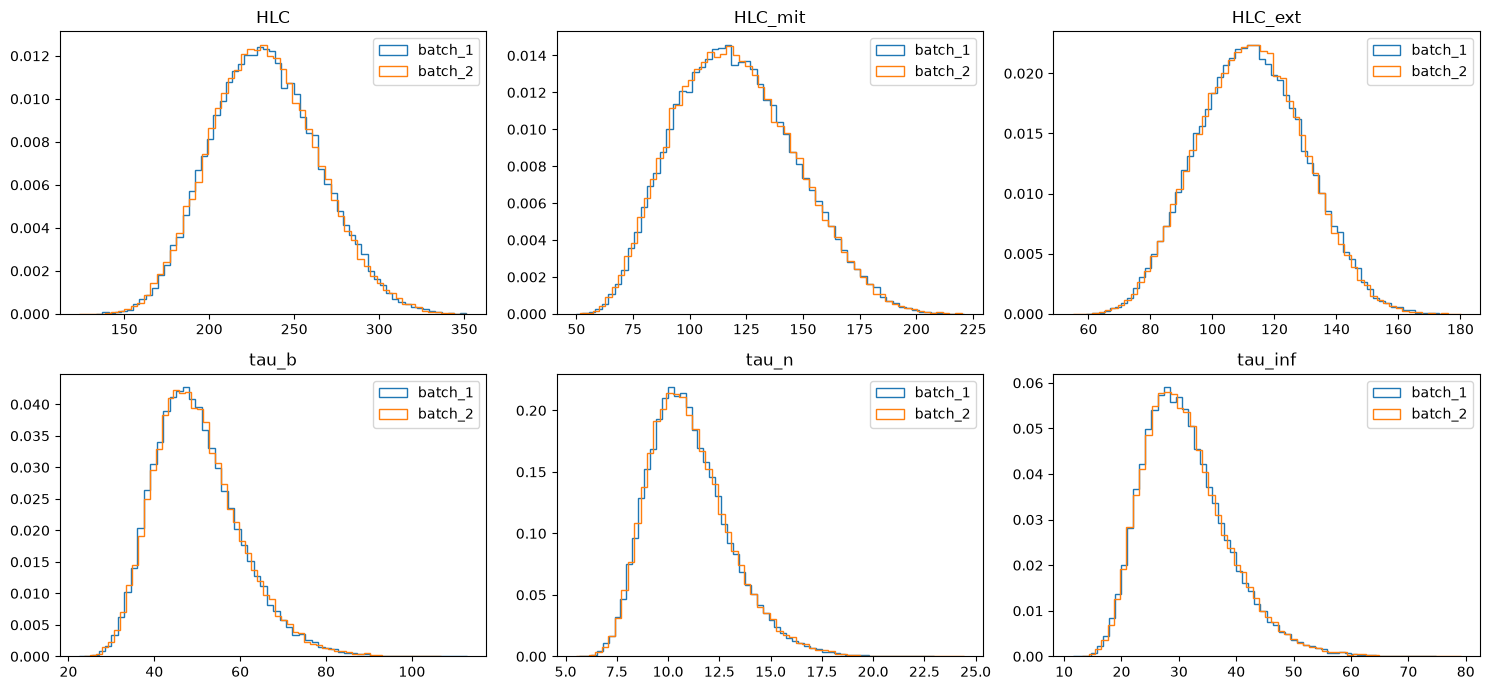

vecteurs de cibles communs aux deux batches : 0


signaux U communs : 1998 sur 2224


In [15]:
b2 = load_single_batch(RAW_DIR / "batch_2.pt")
T2, U2 = b2.indoor_temperature, b2.indoor_U
y2 = torch.cat([b2.HLC.unsqueeze(1), b2.Hb, b2.CDT], dim=1)
df_y2 = pd.DataFrame(y2.numpy(), columns=indicators_labels)

# structure et excitation
s2 = pd.DataFrame(b2.solicitation.numpy(), columns=b2.solicitation_field_names)
print("mêmes champs de sollicitation :", list(s2.columns) == list(df_s.columns))
print("paramètres qui varient :", list(s2.columns[s2.nunique() > 1]))
print("valeurs de U :", torch.unique(U2).tolist(), "| T0 :", torch.unique(T2[:, 0]).tolist())
print("max |HLC - sum(Hb)| :", (b2.HLC - b2.Hb.sum(1)).abs().max().item())

def familles(U: torch.Tensor) -> pd.Series:
    """Répartition (%) des familles d'excitation, avec les mêmes règles qu'en section 2."""
    n_sw = (U[:, 1:] != U[:, :-1]).sum(1).numpy()
    E = U.sum(1).numpy()
    frac = (U > 0).float().mean(1).numpy()
    f = np.select([E == 0, frac == 1, n_sw == 1, n_sw == 2, n_sw <= 10],
                  ["sans chauffage", "toujours en marche", "1 échelon", "1 créneau", "3 à 10 commutations"],
                  default="PRBS rapide (> 10)")
    return pd.Series(f).value_counts(normalize=True).mul(100).round(1)

display(pd.DataFrame({"batch_1": familles(U), "batch_2": familles(U2)}))

# distributions des cibles
cols = ["mean", "std", "min", "50%", "max"]
display(pd.concat({"batch_1": df_y.describe().T[cols], "batch_2": df_y2.describe().T[cols]}, axis=1).round(2))

def ks_stat(a: np.ndarray, c: np.ndarray) -> float:
    """Statistique de Kolmogorov-Smirnov à deux échantillons."""
    a, c = np.sort(a), np.sort(c)
    grid = np.concatenate([a, c])
    return float(np.max(np.abs(np.searchsorted(a, grid, side="right") / len(a)
                               - np.searchsorted(c, grid, side="right") / len(c))))

ks_seuil = 1.36 * np.sqrt(2 / len(df_y))      # seuil à 5 % pour deux échantillons de 50 000
display(pd.Series({l: ks_stat(df_y[l].values, df_y2[l].values) for l in indicators_labels}, name="KS").round(4))
print(f"seuil KS à 5 % : {ks_seuil:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), indicators_labels):
    ax.hist(df_y[col], bins=60, histtype="step", density=True, label="batch_1")
    ax.hist(df_y2[col], bins=60, histtype="step", density=True, label="batch_2")
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

# recouvrements
both_y = torch.cat([indicators, y2])
print("vecteurs de cibles communs aux deux batches :", len(both_y) - torch.unique(both_y, dim=0).shape[0])
u1, u2 = torch.unique(U, dim=0), torch.unique(U2, dim=0)
print(f"signaux U communs : {len(u1) + len(u2) - torch.unique(torch.cat([u1, u2]), dim=0).shape[0]} sur {len(u2)}")

### Conclusions de la section 6

| Vérification | `batch_1` | `batch_2` | Verdict |
|---|---|---|---|
| Structure, champs, $\text{HLC} = \sum H_b$ | identiques | identiques | ✔ |
| Excitation | PRBS 0/7000 W, mêmes 3 paramètres actifs | idem, **aucune sinusoïde** | ✔ |
| Familles d'excitation | 31,8 / 29,1 / 22,2 / 8,5 / 7,5 / 0,8 % | 31,9 / 29,2 / 22,2 / 8,3 / 7,6 / 0,9 % | ✔ |
| État initial | 24,624 °C | 24,624 °C | ✔ |
| Moyennes des cibles | HLC 233,1 ; $\tau_b$ 50,0 | HLC 232,7 ; $\tau_b$ 50,1 | ✔ |
| KS des 6 cibles | — | 0,004 à 0,007, sous le seuil de 0,0086 | même distribution |
| Bâtiments communs | — | 0 | ✔ aucune fuite entre batches |
| Signaux $U$ communs | 2243 | 1998 sur 2224 | même générateur (graine fixe) |

**Conclusion** : `batch_2` est statistiquement indiscernable de `batch_1`, et les deux ne partagent aucun bâtiment. Une vérification complémentaire sur `batch_10` (hors notebook) donne le même résultat : KS ≤ 0,007 pour 5 cibles, 0,0098 pour $\tau_n$ (légèrement au-dessus du seuil, mais écart de moyenne de 0,02 h, sans portée pratique sur 12 tests), 0 bâtiment commun, aucune sinusoïde.

Conséquences :
- les conclusions de l'exploration sur `batch_1` valent pour l'ensemble du dataset ;
- on peut **découper par batch** (par exemple 16 pour l'entraînement, 2 pour la validation, 2 pour le test) sans fuite de bâtiment ;
- le dataset ne contient **que des PRBS** (vérifié sur 3 batches) : le modèle ne sera pas évalué sur des excitations sinusoïdales.

# 7. Bilan et décisions pour la modélisation

| Question | Réponse | Décision pour la modélisation |
|---|---|---|
| Que contient une simulation ? | 480 minutes de $U$ (PRBS 0/7000 W) et de $T_{int}$, depuis un état initial commun hors équilibre | entrée du modèle : les deux séries $(T_{int}, U)$ |
| L'excitation biaise-t-elle les cibles ? | non, $\lvert\text{corr}\rvert \le 0{,}01$ | l'information est dans la réponse |
| Les simulations sont-elles indépendantes ? | oui : bâtiments distincts, ordre aléatoire, aucun bâtiment commun entre batches (section 6) | découpage par batch |
| Quelles cibles sont redondantes ? | HLC = $\sum H_b$ ; $\tau_b \approx \tau_\infty$ (0,97) | prédire 5 sorties ($H_b$ et les 3 $\tau$) et obtenir HLC par somme ; $\tau_b$ et $\tau_\infty$ restent deux sorties car l'énoncé demande les deux |
| Quelle normalisation ? | $\tau$ asymétriques, symétriques en log | standardiser HLC et $H_b$ ; log puis standardiser les $\tau$ |
| Où est l'information ? | dans la forme locale autour des commutations ; les $\tau$ en combinaison avec le HLC | un réseau qui lit la dynamique (convolutions / récurrence), pas des grandeurs globales |
| Quelles simulations seront difficiles ? | 8,5 % sans chauffage ; signaux à une seule commutation | évaluer l'erreur par famille d'excitation |

Ces conclusions, établies sur `batch_1`, valent pour l'ensemble du dataset (section 6).

**Remarque sur la résolution de la température.** Cette exploration utilise $T_{int}$ à sa précision de stockage (environ $10^{-6}$ °C). L'exemple de chargement de l'énoncé arrondit la température à 0,01 °C, ce qui correspond mieux à un capteur réel : le modèle final est donc entraîné et évalué sur des données arrondies. Les conclusions qualitatives de ce notebook restent valables ; l'effet de l'arrondi est mesuré dans le notebook 4 (section 5).